# Кредитный скоринг · Разведочный анализ

## Краткие результаты

- **1 526 659** уникальных размеченных кейсов за **92 недели**. В периоде разработки **1 129 770** кейсов, доля дефолтов **3,13%**.
- `static_0` покрывает **100%** кейсов периода разработки. Покрытие `static_cb_0` — **97,7%**, медианная доля пропусков по её признакам после соединения — **92,9%**.
- Для итоговой оценки выделено **203 345** кейсов с **26 мая по 5 октября 2020 года**. Доля дефолтов рассчитана только на периоде разработки.

## Контекст и методика

Единица наблюдения — кредитный кейс. Бинарный таргет отражает факт дефолта по определению Home Credit. Анализ охватывает размеченные кейсы.

Разбиение проходит по границам недель принятия решений. Последний период зарезервирован для оценки. Перед имитацией запуска модели на конкретную дату нужно уточнить горизонт наблюдения таргета и определить необходимый интервал между периодами.

[Источник и описание признаков](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/data)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw_dir = project_root / "data" / "raw"
train_dir = raw_dir / "parquet_files" / "train"
base_path = train_dir / "train_base.parquet"

plt.rcParams.update({"figure.figsize": (10, 3.4), "axes.grid": True,
                     "grid.alpha": 0.2, "axes.spines.top": False,
                     "axes.spines.right": False})

## Данные

### Проверка базовой таблицы

In [2]:
if not base_path.is_file():
    raise FileNotFoundError(f"Файл {base_path} отсутствует. Инструкция по загрузке есть в README.md.")

base = pd.read_parquet(base_path, columns=["case_id", "date_decision", "WEEK_NUM", "target"])
base["date_decision"] = pd.to_datetime(base["date_decision"], errors="raise")
assert base.notna().all().all()
assert base["case_id"].is_unique
assert set(base["target"].unique()) == {0, 1}

weeks = sorted(base["WEEK_NUM"].unique())
assert len(weeks) >= 10
calibration_start = weeks[int(0.60 * len(weeks))]
evaluation_start = weeks[int(0.80 * len(weeks))]
development = base.loc[base["WEEK_NUM"] < calibration_start].copy()

window = pd.Series("Разработка", index=base.index)
window.loc[base["WEEK_NUM"] >= calibration_start] = "Калибровка и порог"
window.loc[base["WEEK_NUM"] >= evaluation_start] = "Итоговая оценка"
split_summary = base.groupby(window, sort=False).agg(
    cases=("case_id", "size"), weeks=("WEEK_NUM", "nunique"),
    first_decision=("date_decision", "min"), last_decision=("date_decision", "max"),
).sort_values("first_decision")
assert (split_summary["last_decision"].iloc[:-1].to_numpy()
        < split_summary["first_decision"].iloc[1:].to_numpy()).all()
display(split_summary.rename(columns={"cases": "Кейсы", "weeks": "Недели",
                                      "first_decision": "Первая дата", "last_decision": "Последняя дата"}))

,Кейсы,Недели,Первая дата,Последняя дата
Разработка,1129770,55,2019-01-01,2020-01-20
Калибровка и порог,193544,18,2020-01-21,2020-05-25
Итоговая оценка,203345,19,2020-05-26,2020-10-05


## Результаты

### Объём и доля дефолтов по неделям в периоде разработки

Кейсы периода разработки: 1,129,770
Доля дефолтов в периоде разработки: 3.13%


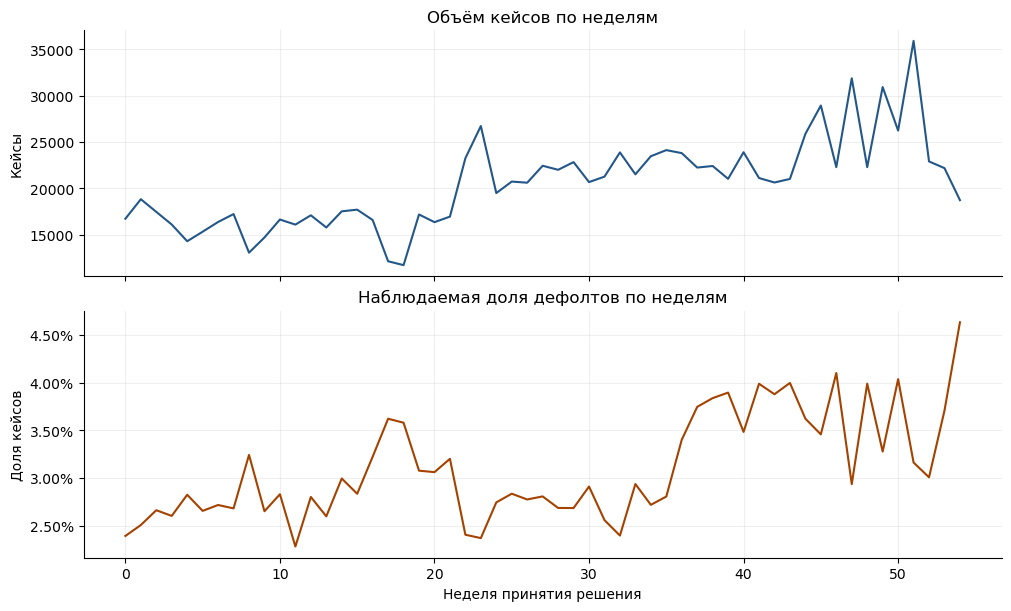

In [3]:
weekly = development.groupby("WEEK_NUM").agg(
    cases=("case_id", "size"), default_rate=("target", "mean"),
)
print(f"Кейсы периода разработки: {len(development):,}")
print(f"Доля дефолтов в периоде разработки: {development['target'].mean():.2%}")

figure, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6), layout="constrained")
weekly["cases"].plot(ax=axes[0], color="#235789", title="Объём кейсов по неделям")
weekly["default_rate"].plot(ax=axes[1], color="#a44200", title="Наблюдаемая доля дефолтов по неделям")
axes[0].set_ylabel("Кейсы")
axes[1].set_ylabel("Доля кейсов")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlabel("Неделя принятия решения")
plt.show()

### Покрытие статических таблиц и пропуски в признаках

В каждой статической таблице ожидается максимум одна запись на кейс.
Покрытие рассчитано на кейсах периода разработки. При расчёте пропусков
учитываются кейсы без совпадения при левом соединении. Чтение столбцов
группами ограничивает использование памяти.

In [4]:
static_tables = {
    "static_0": sorted(train_dir.glob("train_static_0_*.parquet")),
    "static_cb_0": sorted(train_dir.glob("train_static_cb_0*.parquet")),
}
development_ids = pd.Index(development["case_id"])
coverage_rows = []
missingness_rows = []

for table_name, paths in static_tables.items():
    if not paths:
        raise FileNotFoundError(f"Файлы Parquet для {table_name} отсутствуют в {train_dir}")
    shards = [pq.ParquetFile(path) for path in paths]
    features = [name for name in shards[0].schema_arrow.names if name != "case_id"]
    assert all(set(shard.schema_arrow.names) == set(features) | {"case_id"} for shard in shards)
    all_ids = pd.Index(pd.concat([
        shard.read(columns=["case_id"]).to_pandas()["case_id"] for shard in shards
    ], ignore_index=True))
    assert not all_ids.hasnans and all_ids.is_unique, table_name

    matched = development_ids.isin(all_ids).sum()
    coverage_rows.append({
        "table": table_name, "Признаки": len(features), "Совпавшие кейсы": matched,
        "Покрытие": matched / len(development),
        "Кейсы вне базы": (~all_ids.isin(base["case_id"])).sum(),
    })

    for start in range(0, len(features), 24):
        columns = features[start:start + 24]
        observed = pd.Series(0, index=columns, dtype="int64")
        for shard in shards:
            for batch in shard.iter_batches(columns=["case_id", *columns]):
                frame = batch.to_pandas()
                mask = frame["case_id"].isin(development_ids)
                observed += frame.loc[mask, columns].count()
        missingness_rows.extend(
            {"table": table_name, "feature": name, "missing share": 1 - count / len(development)}
            for name, count in observed.items()
        )

coverage = pd.DataFrame(coverage_rows).set_index("table")
missingness = pd.DataFrame(missingness_rows)
display(coverage.style.format({"Покрытие": "{:.1%}"}))

,Признаки,Совпавшие кейсы,Покрытие,Кейсы вне базы
table,,,,
static_0,167,1129770,100.0%,0
static_cb_0,52,1103893,97.7%,0


### Признаки с наибольшей долей пропусков

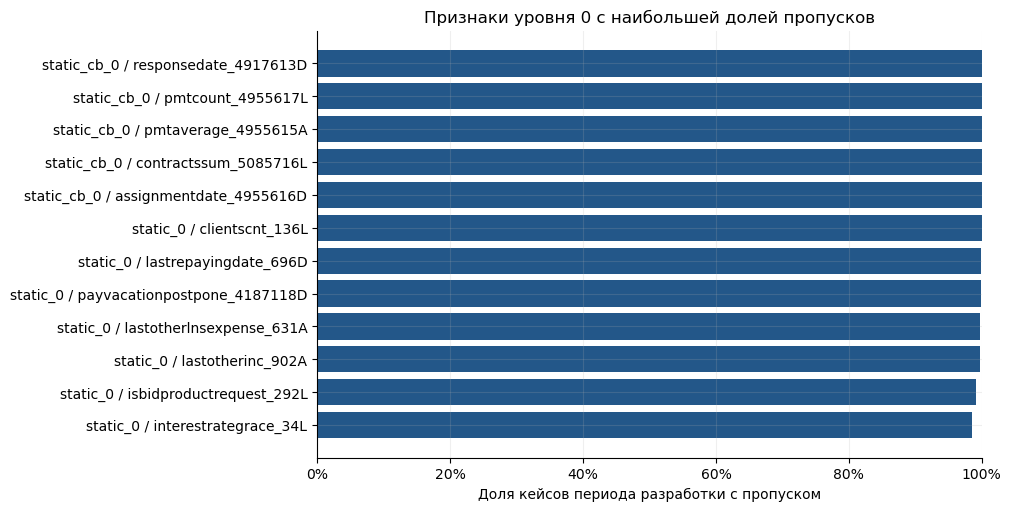

,Медиана доли пропусков,Полностью пустые признаки
table,,
static_0,31.3%,0
static_cb_0,92.9%,5


In [5]:
top_missing = missingness.nlargest(12, "missing share").sort_values("missing share")
labels = top_missing["table"] + " / " + top_missing["feature"]
figure, axis = plt.subplots(figsize=(10, 5), layout="constrained")
axis.barh(labels, top_missing["missing share"], color="#235789")
axis.xaxis.set_major_formatter(PercentFormatter(1))
axis.set(xlim=(0, 1), xlabel="Доля кейсов периода разработки с пропуском",
         title="Признаки уровня 0 с наибольшей долей пропусков")
plt.show()

display(missingness.groupby("table")["missing share"].agg(
    median="median", fully_missing=lambda values: values.eq(1).sum()
).rename(columns={"median": "Медиана доли пропусков",
                  "fully_missing": "Полностью пустые признаки"})
  .style.format({"Медиана доли пропусков": "{:.1%}"}))

## Выводы

Левое соединение сохраняет кейсы без записи в бюро. Пять признаков
`static_cb_0` полностью отсутствуют в периоде разработки. Вклад остальных
признаков бюро можно проверить на более позднем периоде.

На разработку приходится около 60% недель и 74,0% кейсов. Для оценки
стабильности полезно измерять качество по неделям наряду с общей метрикой.